# Distribuciones discretas: binomial, hipergeométrica y de Poisson

Desarrollo de los ejercicios sobre distribuciones discretas de probabilidad: binomial,
hipergeométrica y de Poisson, con sus características, parámetros y relaciones de aproximación.
Cada modelo se define con su función de probabilidad, sus condiciones de uso y sus momentos; en
Python se implementan los cálculos con `math.comb` y `math.exp` y se contrastan por simulación
Monte Carlo con semilla fija. Las secciones 6 a 8 comparan explícitamente las tres distribuciones
para mostrar cuándo una aproxima a otra y cuándo la aproximación deja de ser válida.

## Marco teórico

### Ensayo de Bernoulli y distribución binomial

Un ensayo de Bernoulli tiene dos resultados posibles, éxito con probabilidad $p$ y fracaso con
$1-p$. Si se realizan $n$ ensayos independientes con la misma $p$, el número de éxitos $X$ sigue
una distribución binomial:

$$X \sim Bin(n, p), \qquad P(X = k) = C(n, k)\, p^{k} (1-p)^{n-k}, \qquad k = 0, 1, \dots, n$$

$$E[X] = n p, \qquad Var(X) = n p (1-p), \qquad \sigma = \sqrt{n p (1-p)}$$

Supuestos que deben cumplirse:

1. Número fijo y conocido de ensayos $n$.
2. Independencia entre ensayos (la probabilidad de éxito no depende de los resultados anteriores).
3. Probabilidad de éxito $p$ constante en todos los ensayos.
4. Cada ensayo se clasifica en exactamente una de dos categorías.

Cuando la extracción se hace sin reposición sobre una población finita, el supuesto 2 se viola y
la binomial deja de ser el modelo correcto.

### Distribución hipergeométrica

Sea una población de $N$ elementos de los cuales $K$ poseen la característica de interés. Se
extraen $n$ elementos sin reposición y se cuenta $X$, el número de elementos con la
característica:

$$X \sim Hip(N, K, n), \qquad P(X = k) = \frac{C(K, k)\, C(N-K,\ n-k)}{C(N, n)}$$

con $\max(0, n - (N-K)) \le k \le \min(n, K)$. Sus momentos son

$$E[X] = n \frac{K}{N}, \qquad Var(X) = n \frac{K}{N} \left(1 - \frac{K}{N}\right) \frac{N-n}{N-1}$$

Supuestos: selección aleatoria simple (todo subconjunto de tamaño $n$ es equiprobable),
extracción sin reposición y población finita. El factor $f = (N-n)/(N-1)$ se llama corrección por
población finita: reduce la varianza respecto de la binomial porque, al no reponer, cada extracción
disminuye la incertidumbre sobre las restantes.

### Distribución de Poisson

Modela el número de eventos que ocurren en un intervalo de tiempo o de espacio cuando los eventos
llegan de manera independiente y a tasa constante:

$$X \sim Pois(\lambda), \qquad P(X = k) = e^{-\lambda} \frac{\lambda^{k}}{k!}, \qquad k = 0, 1, 2, \dots$$

$$E[X] = Var(X) = \lambda$$

Supuestos: los eventos de intervalos disjuntos son independientes, la probabilidad de dos o más
eventos en un intervalo infinitesimal es despreciable, y la tasa media $\lambda$ es constante en
todo el periodo. La igualdad $E[X] = Var(X)$ es una condición de verificación práctica: si los
datos muestran varianza muy distinta de la media, el modelo Poisson no es apropiado.

### Relaciones de aproximación

**Binomial a Poisson.** Si $n$ es grande, $p$ es pequeño y el producto $\lambda = n p$ permanece
aproximadamente constante, entonces $(1-p)^n \to e^{-n p}$ y

$$P(X = k) = C(n, k) p^k (1-p)^{n-k} \approx e^{-\lambda} \frac{\lambda^k}{k!}$$

La aproximación es buena cuando $n \ge 20$ y $p \le 0.05$, o en general cuando $n p \le 7$.

**Hipergeométrica a binomial.** Si la fracción extraída $n/N$ es pequeña, la reposición deja de
influir y la probabilidad de éxito se mantiene casi constante entre ensayos:

$$Hip(N, K, n) \approx Bin\left(n, \frac{K}{N}\right) \qquad \text{si } \frac{n}{N} \lesssim 0.05$$

**Binomial a hipergeométrica.** En el sentido inverso, cuando $n/N$ deja de ser pequeño la
hipergeométrica decae más rápido que la binomial: la muestra consume elementos del lote y la
probabilidad de no detectar defectos disminuye. La sección 8 cuantifica esa brecha.

In [1]:
import itertools
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"


def bin_pmf(k, n, p):
    """P(X = k) para X ~ Bin(n, p)."""
    if k < 0 or k > n:
        return 0.0
    return math.comb(n, k) * p ** k * (1 - p) ** (n - k)


def hip_pmf(k, N, K, n):
    """P(X = k) para X ~ Hip(N, K, n): N elementos, K con la característica, n extraídos."""
    if k < 0 or k > K or n - k < 0 or n - k > N - K:
        return 0.0
    return math.comb(K, k) * math.comb(N - K, n - k) / math.comb(N, n)


def pois_pmf(k, lam):
    """P(X = k) para X ~ Pois(lam)."""
    if k < 0:
        return 0.0
    return math.exp(-lam) * lam ** k / math.factorial(k)


print("numpy", np.__version__, "| matplotlib", mpl.__version__)

numpy 2.5.4 | matplotlib 3.11.2


## 1. Accidentes de tránsito atribuibles al exceso de velocidad

Sea $X$ el número de accidentes, entre 8 observados al azar, atribuibles al exceso de velocidad.
El 60% de los accidentes se debe a esa causa, de modo que cada observación es un ensayo de
Bernoulli con $p = 0.60$ y los 8 accidentes se suponen independientes:

$$X \sim Bin(8,\ 0.60), \qquad E[X] = 8(0.60) = 4.8, \qquad Var(X) = 8(0.60)(0.40) = 1.92$$

### a) Seis por exceso de velocidad

$$P(X = 6) = C(8, 6)\, (0.60)^{6} (0.40)^{2} = 28(0.046656)(0.16) = 0.2090$$

### b) Más de cuatro

$$P(X > 4) = \sum_{k=5}^{8} P(X = k) = 0.2787 + 0.2090 + 0.0896 + 0.0168 = 0.5941$$

### c) Entre 2 y 6

$$P(2 \le X \le 6) = 1 - P(X \le 1) - P(X = 7) - P(X = 8) = 1 - 0.0085 - 0.0896 - 0.0168 = 0.8851$$

Supuestos: los 8 accidentes son independientes entre sí, la probabilidad de exceso de velocidad es
constante en todos ellos y cada accidente se clasifica en una única categoría. La independencia
entre accidentes de tránsito es una idealización operativa: se justifica por la selección al azar
de la observación sobre un flujo amplio, donde la causa de un accidente no informa sobre la del
siguiente.

In [2]:
n1, p1 = 8, 0.60

pa = bin_pmf(6, n1, p1)
pb = sum(bin_pmf(k, n1, p1) for k in range(5, n1 + 1))
pc = sum(bin_pmf(k, n1, p1) for k in range(2, 7))

print(f"X ~ Bin({n1}, {p1})   E[X] = {n1 * p1:.4f}   Var = {n1 * p1 * (1 - p1):.4f}")
print(f"a) P(X = 6)        = {pa:.4f}")
print(f"b) P(X > 4)        = {pb:.4f}")
print(f"c) P(2 <= X <= 6)  = {pc:.4f}")
print("normalizacion:", round(sum(bin_pmf(k, n1, p1) for k in range(n1 + 1)), 12))

# verificacion por simulacion
rng = np.random.default_rng(11)
n_sim = 200_000
X_sim = (rng.random((n_sim, n1)) < p1).sum(axis=1)
print("\nsimulacion con M = 200 000 accidentes")
print("a) teorica 0.2090 | simulada", round((X_sim == 6).mean(), 4))
print("b) teorica 0.5941 | simulada", round((X_sim > 4).mean(), 4))
print("c) teorica 0.8851 | simulada", round(((X_sim >= 2) & (X_sim <= 6)).mean(), 4))

X ~ Bin(8, 0.6)   E[X] = 4.8000   Var = 1.9200
a) P(X = 6)        = 0.2090
b) P(X > 4)        = 0.5941
c) P(2 <= X <= 6)  = 0.8851
normalizacion: 1.0

simulacion con M = 200 000 accidentes
a) teorica 0.2090 | simulada 0.2082
b) teorica 0.5941 | simulada 0.5943
c) teorica 0.8851 | simulada 0.8852


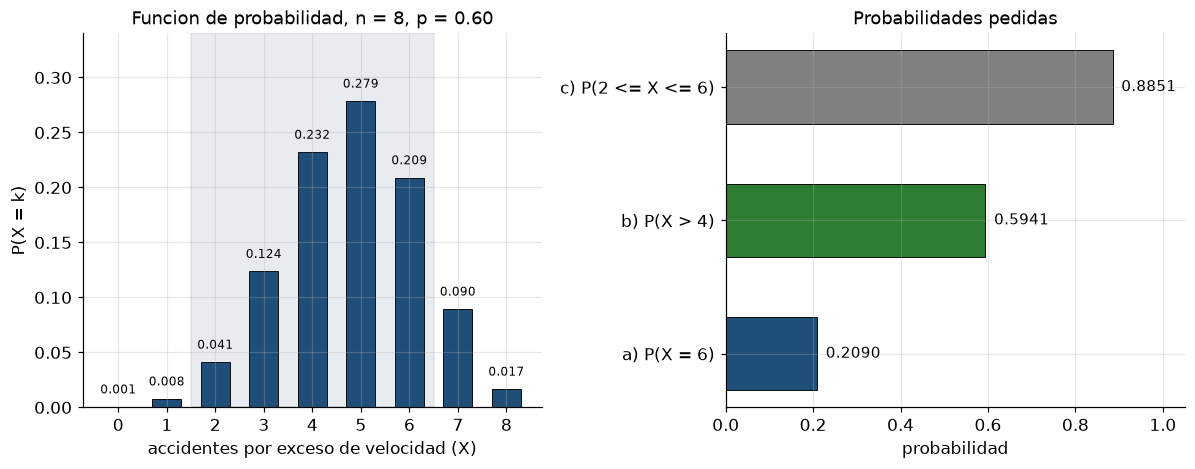

In [3]:
ks1 = np.arange(n1 + 1)
pmf1 = [bin_pmf(k, n1, p1) for k in ks1]

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

axs[0].bar(ks1, pmf1, width=0.6, color=AZUL, edgecolor="black", linewidth=0.6)
for k, v in zip(ks1, pmf1):
    axs[0].text(k, v + 0.012, f"{v:.3f}", ha="center", fontsize=8)
axs[0].axvspan(1.5, 6.5, color=AZUL, alpha=0.10)
axs[0].set_xticks(ks1)
axs[0].set_xlabel("accidentes por exceso de velocidad (X)")
axs[0].set_ylabel("P(X = k)")
axs[0].set_ylim(0, 0.34)
axs[0].set_title("Funcion de probabilidad, n = 8, p = 0.60")

etiquetas = ["a) P(X = 6)", "b) P(X > 4)", "c) P(2 <= X <= 6)"]
valores1 = [pa, pb, pc]
colores1 = [AZUL, VERDE, GRIS]
axs[1].barh(etiquetas, valores1, color=colores1, edgecolor="black", linewidth=0.6, height=0.55)
for i, v in enumerate(valores1):
    axs[1].text(v + 0.02, i, f"{v:.4f}", va="center", fontsize=10)
axs[1].set_xlim(0, 1.05)
axs[1].set_xlabel("probabilidad")
axs[1].set_title("Probabilidades pedidas")

plt.tight_layout()
plt.show()

## 2. Detención de un proceso de producción

Sea $X$ el número de unidades defectuosas en una muestra de 5 unidades escogidas con sustitución.
El proceso se detiene cuando $X \ge 2$. Con probabilidad de defecto $p$:

$$P(\text{detención}) = P(X \ge 2) = 1 - P(X = 0) - P(X = 1) = 1 - (1-p)^{5} - 5p(1-p)^{4}$$

### a) 20% de defectuosos

$$P(X \ge 2) = 1 - (0.80)^{5} - 5(0.20)(0.80)^{4} = 1 - 0.32768 - 0.40960 = 0.2627$$

### b) 10% de defectuosos

$$P(X \ge 2) = 1 - (0.90)^{5} - 5(0.10)(0.90)^{4} = 1 - 0.59049 - 0.32805 = 0.0815$$

Con la misma regla de detención, reducir la tasa de defectos de 0.20 a 0.10 baja la probabilidad
de parada de 0.2627 a 0.0815. La regla es sensible a la calidad del proceso: una baja de diez
puntos porcentuales en la tasa de defecto multiplica por más de tres la probabilidad de no detener
la línea.

Supuestos: la muestra se toma con sustitución (ensayos independientes con $p$ constante), las
unidades se clasifican como defectuosas o conformes, y el umbral de detención es exactamente dos
defectuosas o más.

In [4]:
n2 = 5


def detencion(p):
    """P(X >= 2) con X ~ Bin(5, p): probabilidad de parada del proceso."""
    return 1 - bin_pmf(0, n2, p) - bin_pmf(1, n2, p)


p_det_a = detencion(0.20)
p_det_b = detencion(0.10)

print(f"a) p = 0.20: 1 - P(0) - P(1) = 1 - {bin_pmf(0, n2, 0.20):.5f} - {bin_pmf(1, n2, 0.20):.5f}"
      f" = {p_det_a:.4f}")
print(f"b) p = 0.10: 1 - P(0) - P(1) = 1 - {bin_pmf(0, n2, 0.10):.5f} - {bin_pmf(1, n2, 0.10):.5f}"
      f" = {p_det_b:.4f}")
print(f"reduccion de la probabilidad de parada: {p_det_a - p_det_b:.4f}")

a) p = 0.20: 1 - P(0) - P(1) = 1 - 0.32768 - 0.40960 = 0.2627
b) p = 0.10: 1 - P(0) - P(1) = 1 - 0.59049 - 0.32805 = 0.0815
reduccion de la probabilidad de parada: 0.1813


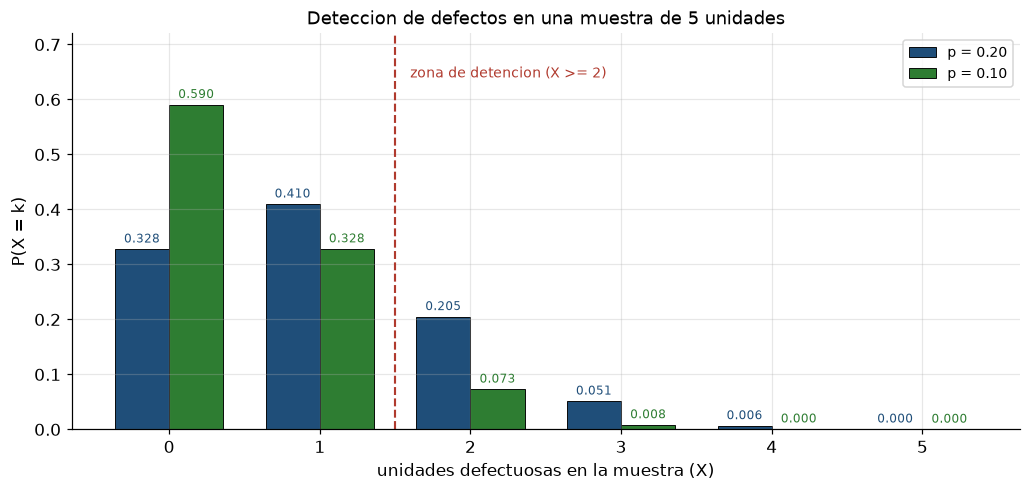

In [5]:
ks2 = np.arange(n2 + 1)
pmf_20 = [bin_pmf(k, n2, 0.20) for k in ks2]
pmf_10 = [bin_pmf(k, n2, 0.10) for k in ks2]

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ancho = 0.36
ax.bar(ks2 - ancho / 2, pmf_20, width=ancho, color=AZUL, edgecolor="black",
       linewidth=0.6, label="p = 0.20")
ax.bar(ks2 + ancho / 2, pmf_10, width=ancho, color=VERDE, edgecolor="black",
       linewidth=0.6, label="p = 0.10")
ax.axvline(1.5, color=ROJO, linestyle="--", linewidth=1.4)
ax.text(1.6, 0.64, "zona de detencion (X >= 2)", fontsize=9, color=ROJO)
for k in ks2:
    ax.text(k - ancho / 2, pmf_20[k] + 0.012, f"{pmf_20[k]:.3f}", ha="center", fontsize=8, color=AZUL)
    ax.text(k + ancho / 2, pmf_10[k] + 0.012, f"{pmf_10[k]:.3f}", ha="center", fontsize=8, color=VERDE)
ax.set_xticks(ks2)
ax.set_xlabel("unidades defectuosas en la muestra (X)")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.72)
ax.set_title("Deteccion de defectos en una muestra de 5 unidades")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 3. Vehículos de otra provincia en un punto de verificación

El 75% de los vehículos es de la provincia de Buenos Aires, de modo que la probabilidad de que un
vehículo sea de otra provincia es $p = 0.25$. Sea $Y$ el número de vehículos de otra provincia
entre los 10 observados; se supone que los vehículos pasan de manera independiente:

$$Y \sim Bin(10,\ 0.25), \qquad E[Y] = 10(0.25) = 2.5, \qquad Var(Y) = 10(0.25)(0.75) = 1.875$$

Se pide la probabilidad de que menos de 4 sean de otra provincia, es decir $Y \le 3$:

$$P(Y \le 3) = \sum_{k=0}^{3} P(Y = k) = 0.0563 + 0.1877 + 0.2816 + 0.2503 = 0.7759$$

Supuestos: los 10 vehículos son independientes entre sí, la proporción 0.75 se mantiene estable en
el punto de verificación (no hay sesgo horario ni de origen), y cada vehículo se clasifica en una
única provincia. El evento pedido es una suma de la cola izquierda, no una probabilidad puntual.

In [6]:
n3, p3 = 10, 0.25

p_menos4 = sum(bin_pmf(k, n3, p3) for k in range(4))

print(f"Y ~ Bin({n3}, {p3})   E[Y] = {n3 * p3:.4f}   Var = {n3 * p3 * (1 - p3):.4f}")
for k in range(4):
    print(f"  P(Y = {k}) = {bin_pmf(k, n3, p3):.4f}")
print(f"P(Y <= 3) = {p_menos4:.4f}")
print("normalizacion:", round(sum(bin_pmf(k, n3, p3) for k in range(n3 + 1)), 12))

Y ~ Bin(10, 0.25)   E[Y] = 2.5000   Var = 1.8750
  P(Y = 0) = 0.0563
  P(Y = 1) = 0.1877
  P(Y = 2) = 0.2816
  P(Y = 3) = 0.2503
P(Y <= 3) = 0.7759
normalizacion: 1.0


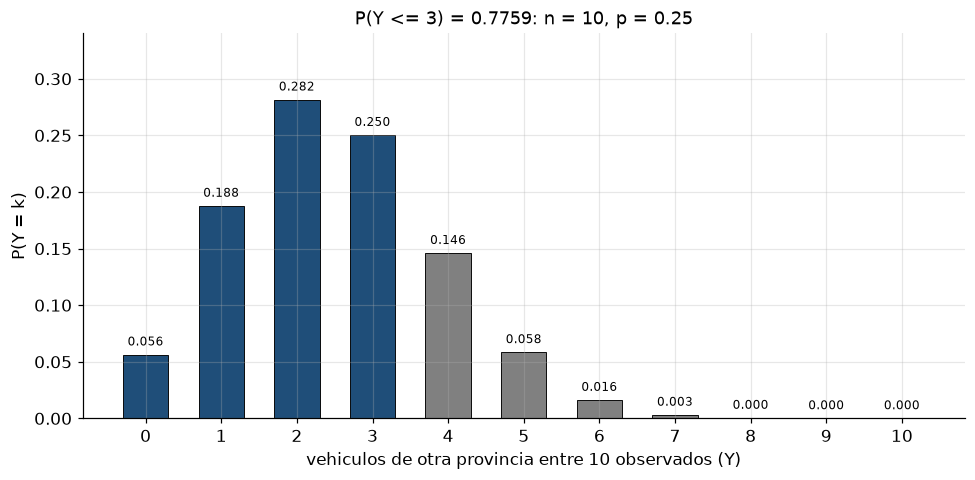

In [7]:
ks3 = np.arange(n3 + 1)
pmf3 = [bin_pmf(k, n3, p3) for k in ks3]

fig, ax = plt.subplots()
colores3 = [AZUL if k < 4 else GRIS for k in ks3]
ax.bar(ks3, pmf3, width=0.6, color=colores3, edgecolor="black", linewidth=0.6)
for k, v in zip(ks3, pmf3):
    ax.text(k, v + 0.008, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(ks3)
ax.set_xlabel("vehiculos de otra provincia entre 10 observados (Y)")
ax.set_ylabel("P(Y = k)")
ax.set_ylim(0, 0.34)
ax.set_title(f"P(Y <= 3) = {p_menos4:.4f}: n = 10, p = 0.25")
plt.tight_layout()
plt.show()

## 4. Automóviles con mancha en el asiento

De 10 automóviles, 2 tienen la mancha; se venden 2 tomados al azar. La extracción es sin
reposición (no se vende dos veces el mismo automóvil), de modo que el número de automóviles con
mancha entre los vendidos sigue una hipergeométrica con $N = 10$, $K = 2$, $n = 2$:

$$P(X = k) = \frac{C(2, k)\, C(8, 2-k)}{C(10, 2)}, \qquad C(10, 2) = 45$$

Los valores posibles son $k = 0, 1, 2$:

| $k$ | Numerador | $P(X = k)$ |
|---|---|---|
| 0 | $C(2,0)\,C(8,2) = 28$ | $28/45 = 0.6222$ |
| 1 | $C(2,1)\,C(8,1) = 16$ | $16/45 = 0.3556$ |
| 2 | $C(2,2)\,C(8,0) = 1$ | $1/45 = 0.0222$ |

### a) Los dos con mancha

$$P(X = 2) = \frac{C(2, 2)\, C(8, 0)}{45} = \frac{1}{45} = 0.0222$$

### b) Al menos uno con mancha

$$P(X \ge 1) = 1 - P(X = 0) = 1 - \frac{28}{45} = \frac{17}{45} = 0.3778$$

La probabilidad de vender los dos automóviles con mancha es baja porque son solo 2 de 10; la
probabilidad de que al menos uno la tenga es más alta porque cualquier par que incluya a uno de
los dos basta.

Supuestos: la venta es una extracción aleatoria simple de 2 unidades sobre las 10, sin reposición
y sin orden relevante (interesa el conjunto vendido, no el orden), y los defectos están
distribuidos de forma indistinguible entre los automóviles.

In [8]:
N4, K4, n4 = 10, 2, 2

ks4 = list(range(min(n4, K4) + 1))
pmf4 = [hip_pmf(k, N4, K4, n4) for k in ks4]

p_ambos = hip_pmf(2, N4, K4, n4)
p_al_menos1 = 1 - hip_pmf(0, N4, K4, n4)

print(f"C({N4}, {n4}) = {math.comb(N4, n4)}")
for k, v in zip(ks4, pmf4):
    print(f"  P(X = {k}) = {v:.4f}")
print(f"a) P(X = 2)   = {p_ambos:.4f}  (1/45 = {1/45:.4f})")
print(f"b) P(X >= 1)  = {p_al_menos1:.4f}  (17/45 = {17/45:.4f})")
print("normalizacion:", round(sum(pmf4), 12))

# verificacion por enumeracion de pares
pares = list(itertools.combinations(range(1, 11), 2))
con_mancha = [{i, j} for i, j in pares if i <= 2 and j <= 2]
alguno = [{i, j} for i, j in pares if i <= 2 or j <= 2]
print("\nenumeracion de los", len(pares), "pares")
print("a) teorica 0.0222 | enumerada", round(len(con_mancha) / len(pares), 4))
print("b) teorica 0.3778 | enumerada", round(len(alguno) / len(pares), 4))

C(10, 2) = 45
  P(X = 0) = 0.6222
  P(X = 1) = 0.3556
  P(X = 2) = 0.0222
a) P(X = 2)   = 0.0222  (1/45 = 0.0222)
b) P(X >= 1)  = 0.3778  (17/45 = 0.3778)
normalizacion: 1.0

enumeracion de los 45 pares
a) teorica 0.0222 | enumerada 0.0222
b) teorica 0.3778 | enumerada 0.3778


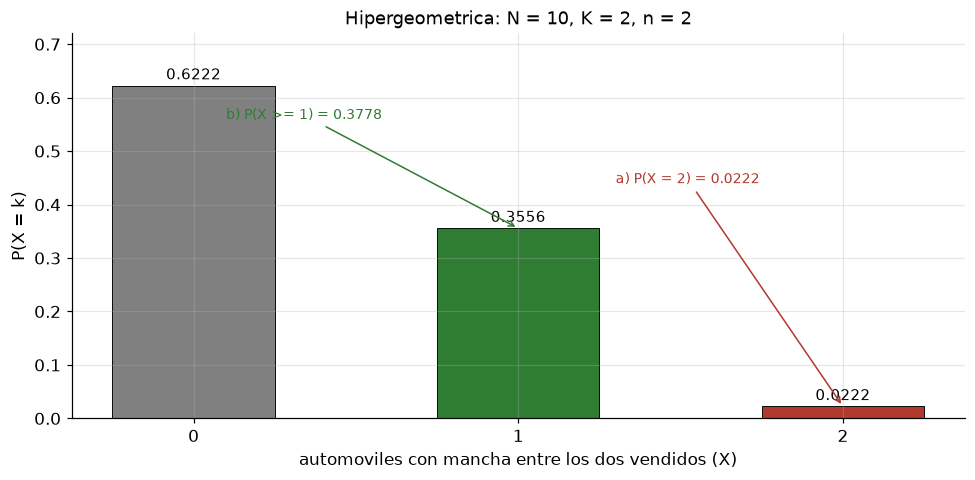

In [9]:
fig, ax = plt.subplots()
colores4 = [ROJO if k == 2 else (VERDE if k == 1 else GRIS) for k in ks4]
ax.bar(ks4, pmf4, width=0.5, color=colores4, edgecolor="black", linewidth=0.6)
for k, v in zip(ks4, pmf4):
    ax.text(k, v + 0.012, f"{v:.4f}", ha="center", fontsize=10)
ax.annotate(f"a) P(X = 2) = {p_ambos:.4f}", xy=(2, p_ambos), xytext=(1.3, 0.44),
            fontsize=9, color=ROJO, arrowprops=dict(arrowstyle="->", color=ROJO, linewidth=1))
ax.annotate(f"b) P(X >= 1) = {p_al_menos1:.4f}", xy=(1, pmf4[1]), xytext=(0.1, 0.56),
            fontsize=9, color=VERDE, arrowprops=dict(arrowstyle="->", color=VERDE, linewidth=1))
ax.set_xticks(ks4)
ax.set_xlabel("automoviles con mancha entre los dos vendidos (X)")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.72)
ax.set_title("Hipergeometrica: N = 10, K = 2, n = 2")
plt.tight_layout()
plt.show()

## 5. Mecanismos de dirección defectuosos en misiles

De 9 misiles, 3 tienen el mecanismo defectuoso; se disparan 3 elegidos al azar. La extracción es
sin reposición, de modo que el número de mecanismos defectuosos entre los disparados sigue una
hipergeométrica con $N = 9$, $K = 3$, $n = 3$:

$$P(X = k) = \frac{C(3, k)\, C(6, 3-k)}{C(9, 3)}, \qquad C(9, 3) = 84$$

### a) Ningún mecanismo defectuoso

$$P(X = 0) = \frac{C(3, 0)\, C(6, 3)}{84} = \frac{20}{84} = 0.2381$$

### b) Más de dos con mecanismo defectuoso

Como el máximo de $X$ es $n = 3$, el evento "más de dos" es exactamente $X = 3$:

$$P(X > 2) = P(X = 3) = \frac{C(3, 3)\, C(6, 0)}{84} = \frac{1}{84} = 0.0119$$

La probabilidad de que los tres disparados tengan el mecanismo defectuoso es mínima porque
requiere que los 3 defectuosos estén entre los 3 elegidos: una sola combinación de las 84
posibles.

Supuestos: los 3 mecanismos defectuosos están distribuidos de forma indistinguible entre los 9
misiles, la selección de los 3 disparados es aleatoria y sin reposición, y no se tiene información
previa sobre qué misiles están afectados.

In [10]:
N5, K5, n5 = 9, 3, 3

ks5 = list(range(min(n5, K5) + 1))
pmf5 = [hip_pmf(k, N5, K5, n5) for k in ks5]

p_ninguno = hip_pmf(0, N5, K5, n5)
p_mas_de_dos = hip_pmf(3, N5, K5, n5)

print(f"C({N5}, {n5}) = {math.comb(N5, n5)}")
for k, v in zip(ks5, pmf5):
    print(f"  P(X = {k}) = {v:.4f}")
print(f"a) P(X = 0) = {p_ninguno:.4f}  (20/84 = {20/84:.4f})")
print(f"b) P(X > 2) = {p_mas_de_dos:.4f}  (1/84 = {1/84:.4f})")
print("normalizacion:", round(sum(pmf5), 12))

# comparacion con la binomial que tendria el mismo p = K/N
p5 = K5 / N5
print("\nbinomial con p = K/N = %.4f:" % p5)
print("  P(X = 0) binomial = %.4f  |  hipergeometrica = %.4f" % (bin_pmf(0, n5, p5), p_ninguno))
print("  n/N = %.4f (la muestra es un tercio del lote)" % (n5 / N5))

C(9, 3) = 84
  P(X = 0) = 0.2381
  P(X = 1) = 0.5357
  P(X = 2) = 0.2143
  P(X = 3) = 0.0119
a) P(X = 0) = 0.2381  (20/84 = 0.2381)
b) P(X > 2) = 0.0119  (1/84 = 0.0119)
normalizacion: 1.0

binomial con p = K/N = 0.3333:
  P(X = 0) binomial = 0.2963  |  hipergeometrica = 0.2381
  n/N = 0.3333 (la muestra es un tercio del lote)


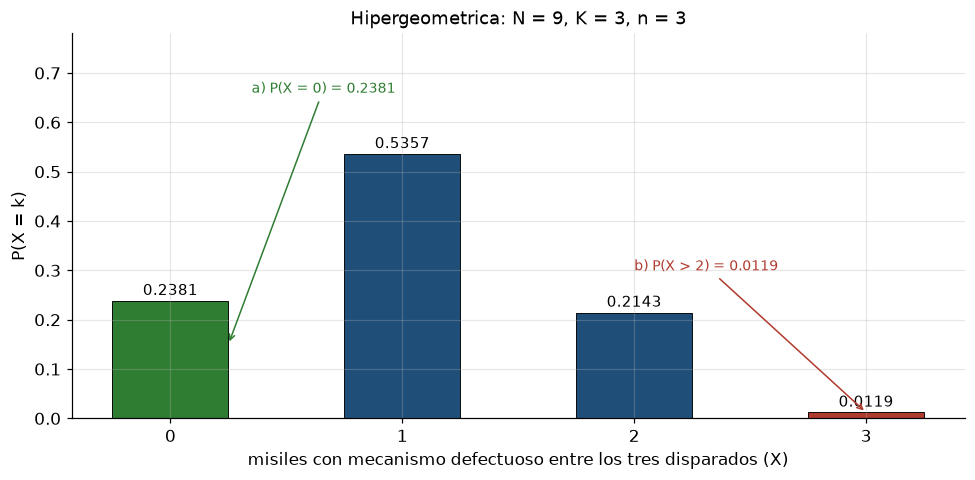

In [11]:
fig, ax = plt.subplots()
colores5 = [VERDE if k == 0 else (ROJO if k == 3 else AZUL) for k in ks5]
ax.bar(ks5, pmf5, width=0.5, color=colores5, edgecolor="black", linewidth=0.6)
for k, v in zip(ks5, pmf5):
    ax.text(k, v + 0.012, f"{v:.4f}", ha="center", fontsize=10)
ax.annotate(f"a) P(X = 0) = {p_ninguno:.4f}", xy=(0.25, 0.15), xytext=(0.35, 0.66),
            fontsize=9, color=VERDE, arrowprops=dict(arrowstyle="->", color=VERDE, linewidth=1))
ax.annotate(f"b) P(X > 2) = {p_mas_de_dos:.4f}", xy=(3, p_mas_de_dos), xytext=(2.0, 0.30),
            fontsize=9, color=ROJO, arrowprops=dict(arrowstyle="->", color=ROJO, linewidth=1))
ax.set_xticks(ks5)
ax.set_xlabel("misiles con mecanismo defectuoso entre los tres disparados (X)")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.78)
ax.set_title("Hipergeometrica: N = 9, K = 3, n = 3")
plt.tight_layout()
plt.show()

## 6. Llamadas de servicio a un centro de mantenimiento

Las llamadas llegan según un proceso de Poisson con promedio $\lambda = 2.5$ llamadas por minuto.
Para intervalos distintos del minuto se escala la tasa proporcionalmente a la duración:
$\lambda(t) = 2.5\, t$ con $t$ en minutos.

### a) No más de 3 en un minuto

$$P(X \le 3) = \sum_{k=0}^{3} e^{-2.5} \frac{2.5^{k}}{k!} = 0.0821 + 0.2052 + 0.2565 + 0.2138 = 0.7576$$

### b) Más de 4 en 72 segundos

72 segundos son $t = 72/60 = 1.2$ minutos, de modo que $\lambda = 2.5(1.2) = 3.0$:

$$P(X > 4) = 1 - \sum_{k=0}^{4} e^{-3.0} \frac{3.0^{k}}{k!} = 1 - 0.8153 = 0.1847$$

### c) Exactamente 7 en 180 segundos

180 segundos son $t = 180/60 = 3$ minutos, de modo que $\lambda = 2.5(3) = 7.5$:

$$P(X = 7) = e^{-7.5} \frac{7.5^{7}}{7!} = (0.0005531)(264.8490) = 0.1465$$

Supuestos: independencia de las llamadas en intervalos disjuntos, tasa constante de 2.5 llamadas
por minuto en todo el periodo observado (no hay horarios de pico), y que la probabilidad de dos
llamadas simultáneas es despreciable. La proporcionalidad de $\lambda$ con la duración del
intervalo es la única transformación aplicada y es consecuencia directa de la estacionariedad del
proceso.

In [12]:
lam6 = 2.5

p_a = sum(pois_pmf(k, lam6) for k in range(4))

lam_b = lam6 * 72 / 60
p_b = 1 - sum(pois_pmf(k, lam_b) for k in range(5))

lam_c = lam6 * 180 / 60
p_c = pois_pmf(7, lam_c)

print(f"a) lambda = {lam6} en 1 min: P(X <= 3) = {p_a:.4f}")
print("   contribuciones:", [round(pois_pmf(k, lam6), 4) for k in range(4)])
print(f"b) 72 s = 1.2 min -> lambda = {lam_b}: P(X > 4) = {p_b:.4f}")
print(f"c) 180 s = 3 min -> lambda = {lam_c}: P(X = 7) = {p_c:.4f}")
print(f"   e^-{lam_c} = {math.exp(-lam_c):.7f}   {lam_c}^7/7! = {lam_c ** 7 / math.factorial(7):.4f}")

a) lambda = 2.5 en 1 min: P(X <= 3) = 0.7576
   contribuciones: [0.0821, 0.2052, 0.2565, 0.2138]
b) 72 s = 1.2 min -> lambda = 3.0: P(X > 4) = 0.1847
c) 180 s = 3 min -> lambda = 7.5: P(X = 7) = 0.1465
   e^-7.5 = 0.0005531   7.5^7/7! = 264.8490


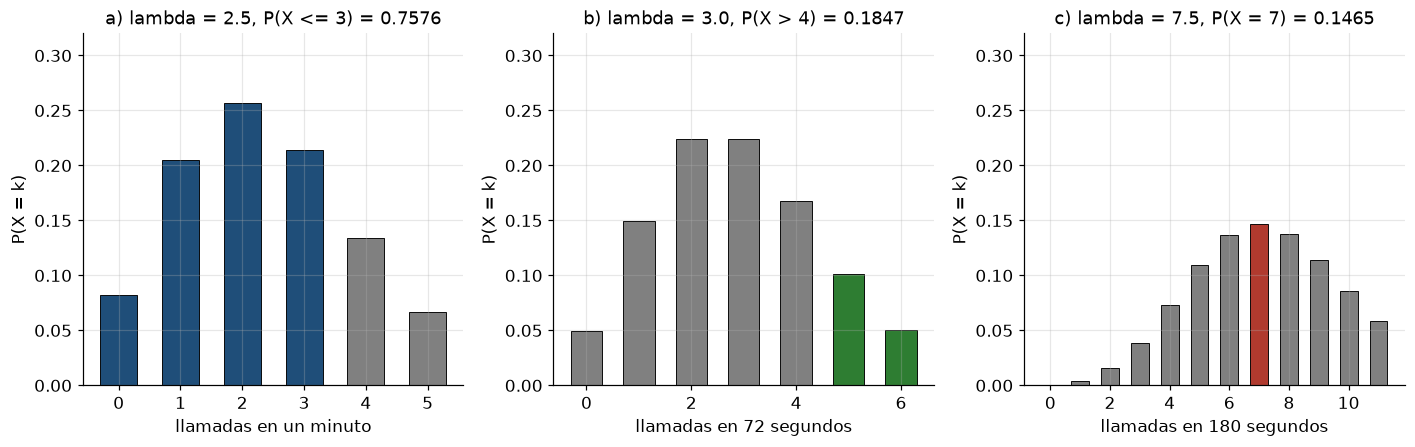

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))

ks_a = np.arange(6)
pmf_a = [pois_pmf(k, lam6) for k in ks_a]
axs[0].bar(ks_a, pmf_a, width=0.6,
           color=[AZUL if k <= 3 else GRIS for k in ks_a], edgecolor="black", linewidth=0.6)
axs[0].set_title(f"a) lambda = {lam6}, P(X <= 3) = {p_a:.4f}")
axs[0].set_xlabel("llamadas en un minuto")

ks_b = np.arange(7)
pmf_b = [pois_pmf(k, lam_b) for k in ks_b]
axs[1].bar(ks_b, pmf_b, width=0.6,
           color=[VERDE if k > 4 else GRIS for k in ks_b], edgecolor="black", linewidth=0.6)
axs[1].set_title(f"b) lambda = {lam_b:.1f}, P(X > 4) = {p_b:.4f}")
axs[1].set_xlabel("llamadas en 72 segundos")

ks_c = np.arange(12)
pmf_c = [pois_pmf(k, lam_c) for k in ks_c]
axs[2].bar(ks_c, pmf_c, width=0.6,
           color=[ROJO if k == 7 else GRIS for k in ks_c], edgecolor="black", linewidth=0.6)
axs[2].set_title(f"c) lambda = {lam_c:.1f}, P(X = 7) = {p_c:.4f}")
axs[2].set_xlabel("llamadas en 180 segundos")

for ax in axs:
    ax.set_ylabel("P(X = k)")
    ax.set_ylim(0, 0.32)

plt.tight_layout()
plt.show()

## 7. Mortalidad por una vacuna contra la gripe

La probabilidad de muerte por la vacuna es $p = 0.00002$ y se administra a 100 000 personas que
constituyen un conjunto independiente de ensayos. El número de muertes $X$ sigue en principio una
binomial con $n = 100\,000$ y $p = 0.00002$:

$$X \sim Bin(100\,000,\ 0.00002), \qquad \lambda = np = 100\,000(0.00002) = 2$$

Como $n$ es grande, $p$ es muy pequeña y $\lambda = 2$ queda acotado, se aplica la aproximación de
Poisson:

$$P(X \le 2) \approx e^{-2} \sum_{k=0}^{2} \frac{2^{k}}{k!} = e^{-2}(1 + 2 + 2) = 5 e^{-2} = 0.676676$$

El valor exacto de la binomial es $0.676676$ y la aproximación de Poisson da el mismo valor
redondeado a seis cifras, con una diferencia del orden de $10^{-11}$. Los términos individuales
no coinciden ($P(0)$ difiere en $2.7 \times 10^{-6}$, con signo opuesto en $P(1)$ y $P(2)$), pero
las diferencias se cancelan en la suma. La cola de una binomial con $n$ grande y $np$ chico se
reproduce con la Poisson sin pérdida de precisión a la escala de trabajo.

Supuestos: ensayos independientes entre las 100 000 personas, probabilidad de muerte constante y
muy pequeña en todas ellas, y que no hay otras causas de muerte atribuibles a la vacuna dentro del
evento considerado. La independencia es la condición habilitante de la aproximación: si las
personas compartieran riesgo (por ejemplo por lote de fabricación), la binomial tampoco sería el
modelo correcto.

In [14]:
n7, p7 = 100_000, 0.00002
lam7 = n7 * p7

p_poisson = sum(pois_pmf(k, lam7) for k in range(3))
p_binom = sum(bin_pmf(k, n7, p7) for k in range(3))

print(f"lambda = n*p = {n7} * {p7} = {lam7}")
print(f"Poisson :  P(X <= 2) = e^-{lam7} * (1 + 2 + 2) = {p_poisson:.6f}")
print(f"Binomial:  P(X <= 2) = {p_binom:.6f}")
print(f"diferencia = {abs(p_poisson - p_binom):.2e}")

lambda = n*p = 100000 * 2e-05 = 2.0
Poisson :  P(X <= 2) = e^-2.0 * (1 + 2 + 2) = 0.676676
Binomial:  P(X <= 2) = 0.676676
diferencia = 7.67e-12


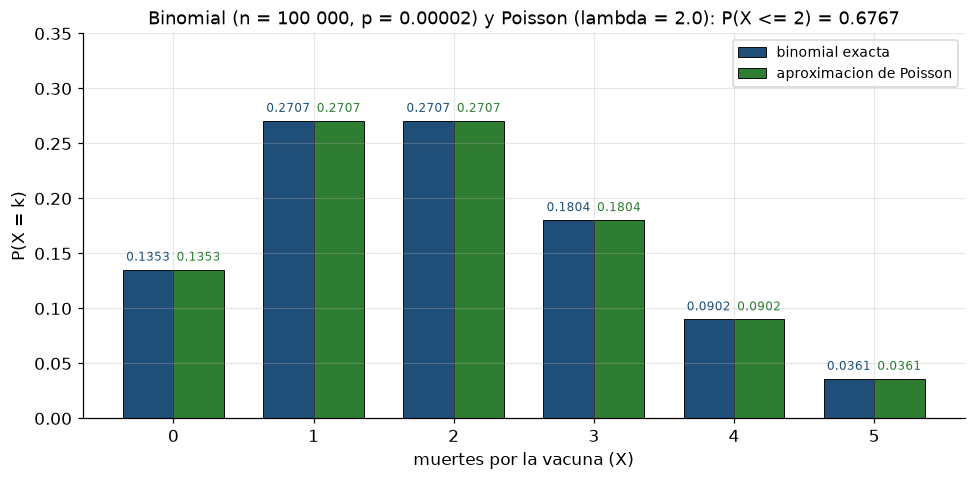

In [15]:
ks7 = np.arange(6)
bin7 = [bin_pmf(k, n7, p7) for k in ks7]
poi7 = [pois_pmf(k, lam7) for k in ks7]

fig, ax = plt.subplots()
ancho7 = 0.36
ax.bar(ks7 - ancho7 / 2, bin7, width=ancho7, color=AZUL, edgecolor="black",
       linewidth=0.6, label="binomial exacta")
ax.bar(ks7 + ancho7 / 2, poi7, width=ancho7, color=VERDE, edgecolor="black",
       linewidth=0.6, label="aproximacion de Poisson")
for k in ks7:
    ax.text(k - ancho7 / 2, bin7[k] + 0.008, f"{bin7[k]:.4f}", ha="center", fontsize=8, color=AZUL)
    ax.text(k + ancho7 / 2, poi7[k] + 0.008, f"{poi7[k]:.4f}", ha="center", fontsize=8, color=VERDE)
ax.set_xticks(ks7)
ax.set_xlabel("muertes por la vacuna (X)")
ax.set_ylabel("P(X = k)")
ax.set_ylim(0, 0.35)
ax.set_title(f"Binomial (n = 100 000, p = 0.00002) y Poisson (lambda = {lam7}):"
             f" P(X <= 2) = {p_poisson:.4f}")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 8. Aceptación de un lote: hipergeométrica, binomial y de Poisson

Se recibe un lote de $N$ unidades con un 5% de defectuosas y se inspeccionan $n = 10$ al azar sin
reposición. El lote se acepta si ninguna unidad inspeccionada resulta defectuosa, de modo que se
pide $P(X = 0)$.

### a) Distribución hipergeométrica ($N = 1000$)

Con $K = 0.05(1000) = 50$ unidades defectuosas:

$$P(X = 0) = \frac{C(50, 0)\, C(950, 10)}{C(1000, 10)} = \prod_{i=0}^{9} \frac{950-i}{1000-i} = 0.5973$$

### b) Aproximación binomial

La binomial supone reposición con $p = K/N = 0.05$:

$$P(X = 0) = (1 - 0.05)^{10} = (0.95)^{10} = 0.5987$$

### c) Aproximación de Poisson

Con $\lambda = n p = 10(0.05) = 0.5$:

$$P(X = 0) = e^{-0.5} = 0.6065$$

Con $n/N = 10/1000 = 0.01$ la fracción extraída es despreciable y la reposición apenas altera la
composición de la muestra. La binomial se desvía de la hipergeométrica en 0.0014 y la Poisson en
0.0092: esta última agrega un error adicional porque sustituye $(1-p)^n$ por $e^{-np}$ y aquí
$np = 0.5$ es pequeño, justo el régimen en el que $(1-p)^n$ y $e^{-np}$ más se separan.

### d) Lote de 40 unidades

Si $N = 40$ entonces $K = 2$ y $n/N = 10/40 = 0.25$: la muestra representa una cuarta parte del
lote y la reposición deja de ser inocua. Solo cambia la hipergeométrica, porque la binomial y la
Poisson no dependen de $N$ sino de $p$ y de $\lambda = n p$, que se mantienen:

| Modelo | $N = 1000$ | $N = 40$ |
|---|---|---|
| Hipergeométrica | 0.5973 | 0.5577 |
| Binomial | 0.5987 | 0.5987 |
| Poisson | 0.6065 | 0.6065 |

Para $N = 40$ la hipergeométrica se reduce a

$$P(X = 0) = \frac{C(38, 10)}{C(40, 10)} = \frac{30 \cdot 29}{40 \cdot 39} = \frac{870}{1560} = 0.5577$$

La binomial sobreestima la probabilidad de aceptación en 0.0410 frente a la hipergeométrica y la
Poisson en 0.0488. Con $n/N$ grande el muestreo sin reposición consume información de la población
y la verdadera probabilidad de no detectar defectos baja. La regla práctica es que la binomial solo
se usa cuando $n/N \lesssim 0.05$; por encima de ese valor la hipergeométrica es obligatoria.

Supuestos: el lote es homogéneo (las defectuosas están distribuidas de forma uniforme), la
inspección es una extracción aleatoria simple sin reposición, y el criterio de aceptación es cero
defectuosas en la muestra.

In [16]:
N8, K8, n8 = 1000, 50, 10
p8 = K8 / N8

p_hip_1000 = hip_pmf(0, N8, K8, n8)
p_bin = bin_pmf(0, n8, p8)
p_poi = pois_pmf(0, n8 * p8)

print(f"lote N = {N8}, K = {K8} (5%), muestra n = {n8}  ->  n/N = {n8 / N8:.3f}")
print(f"a) hipergeometrica: P(X = 0) = C({N8 - K8}, {n8}) / C({N8}, {n8}) = {p_hip_1000:.6f}")
print(f"b) binomial, p = {p8}: P(X = 0) = (1 - {p8})^10 = {p_bin:.6f}")
print(f"c) poisson, lambda = {n8 * p8}: P(X = 0) = e^-{n8 * p8} = {p_poi:.6f}")
print(f"   error binomial  vs hipergeometrica = {abs(p_bin - p_hip_1000):.6f}")
print(f"   error poisson   vs hipergeometrica = {abs(p_poi - p_hip_1000):.6f}")

lote N = 1000, K = 50 (5%), muestra n = 10  ->  n/N = 0.010
a) hipergeometrica: P(X = 0) = C(950, 10) / C(1000, 10) = 0.597311
b) binomial, p = 0.05: P(X = 0) = (1 - 0.05)^10 = 0.598737
c) poisson, lambda = 0.5: P(X = 0) = e^-0.5 = 0.606531
   error binomial  vs hipergeometrica = 0.001426
   error poisson   vs hipergeometrica = 0.009219


In [17]:
N8b, K8b = 40, 2

p_hip_40 = hip_pmf(0, N8b, K8b, n8)

print(f"d) lote N = {N8b}, K = {K8b} (5%), muestra n = {n8}  ->  n/N = {n8 / N8b:.2f}")
print(f"   hipergeometrica: P(X = 0) = C({N8b - K8b}, {n8}) / C({N8b}, {n8}) = {p_hip_40:.6f}")
print(f"   binomial (no cambia): {p_bin:.6f}")
print(f"   poisson  (no cambia): {p_poi:.6f}")
print(f"   la binomial sobreestima en {p_bin - p_hip_40:.4f}")
print(f"   la poisson  sobreestima en {p_poi - p_hip_40:.4f}")

d) lote N = 40, K = 2 (5%), muestra n = 10  ->  n/N = 0.25
   hipergeometrica: P(X = 0) = C(38, 10) / C(40, 10) = 0.557692
   binomial (no cambia): 0.598737
   poisson  (no cambia): 0.606531
   la binomial sobreestima en 0.0410
   la poisson  sobreestima en 0.0488


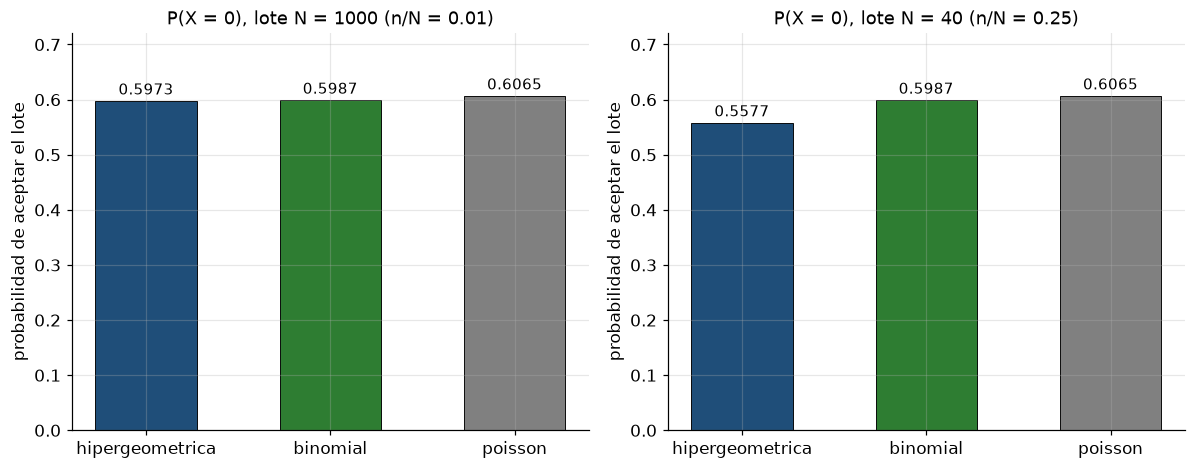

In [18]:
modelos = ["hipergeometrica", "binomial", "poisson"]
val_1000 = [p_hip_1000, p_bin, p_poi]
val_40 = [p_hip_40, p_bin, p_poi]

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

axs[0].bar(modelos, val_1000, width=0.55, color=[AZUL, VERDE, GRIS],
           edgecolor="black", linewidth=0.6)
for i, v in enumerate(val_1000):
    axs[0].text(i, v + 0.012, f"{v:.4f}", ha="center", fontsize=10)
axs[0].set_ylim(0, 0.72)
axs[0].set_title("P(X = 0), lote N = 1000 (n/N = 0.01)")

axs[1].bar(modelos, val_40, width=0.55, color=[AZUL, VERDE, GRIS],
           edgecolor="black", linewidth=0.6)
for i, v in enumerate(val_40):
    axs[1].text(i, v + 0.012, f"{v:.4f}", ha="center", fontsize=10)
axs[1].set_ylim(0, 0.72)
axs[1].set_title("P(X = 0), lote N = 40 (n/N = 0.25)")

for ax in axs:
    ax.set_ylabel("probabilidad de aceptar el lote")

plt.tight_layout()
plt.show()

## Notas de validación

- Las masas de probabilidad se normalizan a 1 en cada sección: binomial en las secciones 1 a 3,
  hipergeométrica en las secciones 4, 5 y 8, y de Poisson en las secciones 6 y 7. La
  normalización se imprime en la salida de cada celda.
- La hipergeométrica de la sección 8 con $N = 1000$ y $n = 10$ da 0.5973; la binomial se separa
  en 0.0014 y con $N = 40$ la diferencia llega a 0.0410, porque $n/N = 0.25$ deja de ser
  despreciable. La corrección por población finita $(N-n)/(N-1)$ explica la reducción de la
  varianza respecto de la binomial.
- La aproximación de Poisson de la sección 7 reproduce a la binomial exacta hasta seis decimales
  ($0.676676$ ambos, diferencia del orden de $10^{-11}$): es el caso típico de $n$ grande y
  $np$ chico.
- Las funciones de probabilidad se implementan con `math.comb` y `math.exp` sin paquetes
  adicionales, y las sumas de cola se calculan de forma explícita para dejar trazable el cómputo.
- Las simulaciones Monte Carlo de la sección 1 usan semilla fija para ser reproducibles y
  convergen al valor teórico con un error del orden de $1/\sqrt{M}$, siendo $M$ el número de
  ensayos.
- Supuestos comunes: ensayos independientes con probabilidad constante para la binomial,
  extracción aleatoria simple sin reposición para la hipergeométrica, y tasa constante con
  independencia en intervalos disjuntos para Poisson.

Referencias: Ross, S. - Probabilidad y estadística para ingeniería y ciencias. Meyer, P. -
Probabilidad y aplicaciones estadísticas. Walpole, R., Myers, R., Myers, S. - Probabilidad y
estadística para ingeniería y ciencias.